In [1]:
import seaborn as sns

In [2]:
df = sns.load_dataset("taxis")

print(df)

                  pickup             dropoff  passengers  distance  fare  \
0    2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0   
1    2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0   
2    2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5   
3    2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0   
4    2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0   
...                  ...                 ...         ...       ...   ...   
6428 2019-03-31 09:51:53 2019-03-31 09:55:27           1      0.75   4.5   
6429 2019-03-31 17:38:00 2019-03-31 18:34:23           1     18.74  58.0   
6430 2019-03-23 22:55:18 2019-03-23 23:14:25           1      4.14  16.0   
6431 2019-03-04 10:09:25 2019-03-04 10:14:29           1      1.12   6.0   
6432 2019-03-13 19:31:22 2019-03-13 19:48:02           1      3.85  15.0   

       tip  tolls  total   color      payment            pickup_zone  \
0     2.15    0

In [3]:
print("First 5 Rows of the Taxis Dataset:")
print(df.head())

First 5 Rows of the Taxis Dataset:
               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhatt

In [4]:
print("Shape of the Dataset:", df.shape)

print("Number of Rows:", df.shape[0])

print("Number of Columns:", df.shape[1])

Shape of the Dataset: (6433, 14)
Number of Rows: 6433
Number of Columns: 14


In [5]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [6]:
missing_values = df.isnull().sum()

print("Columns with Missing Values:")
print(missing_values[missing_values > 0])

Columns with Missing Values:
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [7]:
for column in df.select_dtypes(include='number').columns:
    df[column] = df[column].fillna(df[column].median())

print("Missing values in numerical columns filled successfully!")

Missing values in numerical columns filled successfully!


In [8]:
for column in df.select_dtypes(include='object').columns:
    df[column] = df[column].fillna(df[column].mode()[0])

print("Missing values in categorical columns filled successfully!")

Missing values in categorical columns filled successfully!


C:\Users\prana\AppData\Local\Temp\ipykernel_53456\1176615838.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include='object').columns:


In [9]:
for column in df.columns:
    if not pd.api.types.is_numeric_dtype(df[column]):
        df[column] = df[column].astype('object')

        if df[column].isnull().sum() > 0:
            df[column] = df[column].fillna(df[column].mode()[0])

print("Missing categorical values filled successfully!")

NameError: name 'pd' is not defined

In [10]:
import pandas as pd

In [11]:
for column in df.columns:
    if not pd.api.types.is_numeric_dtype(df[column]):
        df[column] = df[column].astype('object')

        if df[column].isnull().sum() > 0:
            df[column] = df[column].fillna(df[column].mode()[0])

print("Missing categorical values filled successfully!")

Missing categorical values filled successfully!


In [12]:
print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [13]:
import matplotlib.pyplot as plt

In [14]:
df['pickup'] = pd.to_datetime(df['pickup'])

print("Pickup column converted to datetime successfully!")

Pickup column converted to datetime successfully!


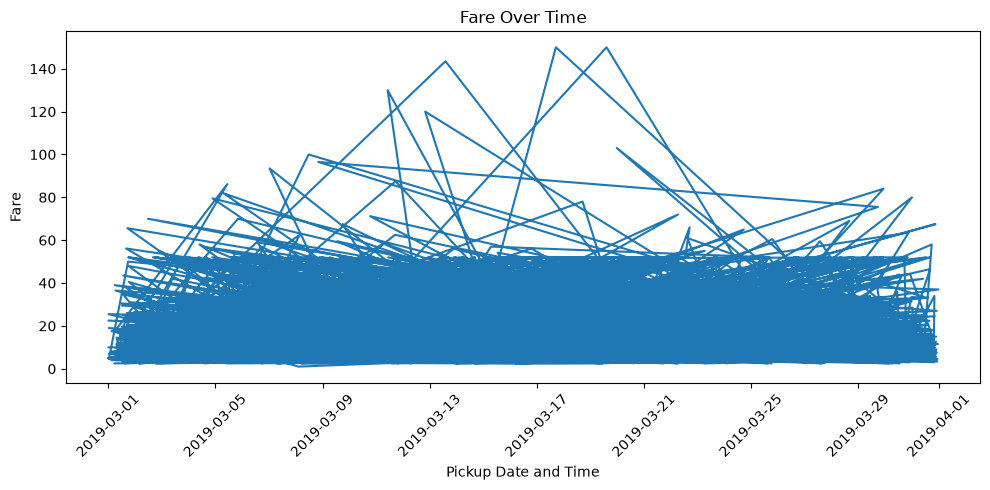

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(df['pickup'], df['fare'])

plt.xlabel("Pickup Date and Time")
plt.ylabel("Fare")

plt.title("Fare Over Time")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

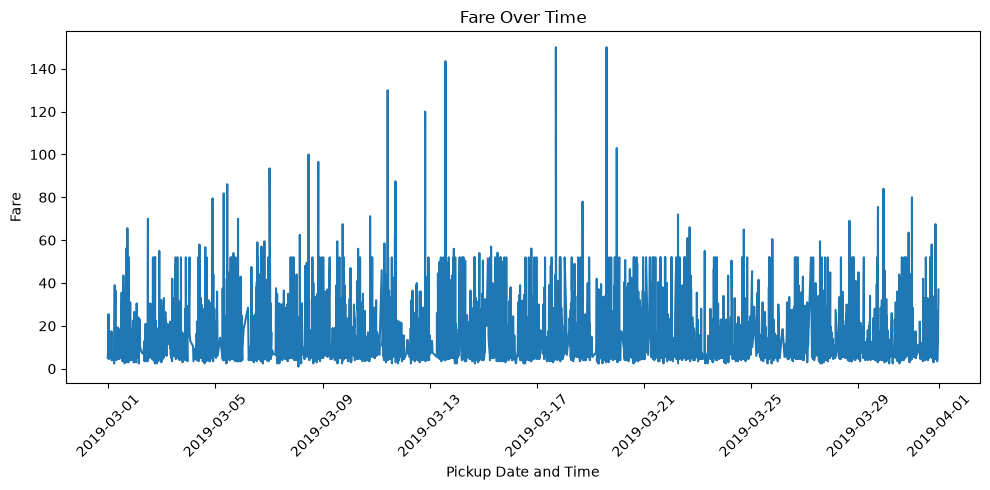

In [16]:
df_sorted = df.sort_values('pickup')

plt.figure(figsize=(10, 5))

plt.plot(df_sorted['pickup'], df_sorted['fare'])

plt.xlabel("Pickup Date and Time")
plt.ylabel("Fare")
plt.title("Fare Over Time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
borough_fare = df.groupby('pickup_borough')['fare'].sum()

print("Total Fare by Pickup Borough:")
print(borough_fare)

Total Fare by Pickup Borough:
pickup_borough
Bronx         2078.91
Brooklyn      6327.48
Manhattan    59426.42
Queens       16382.06
Name: fare, dtype: float64


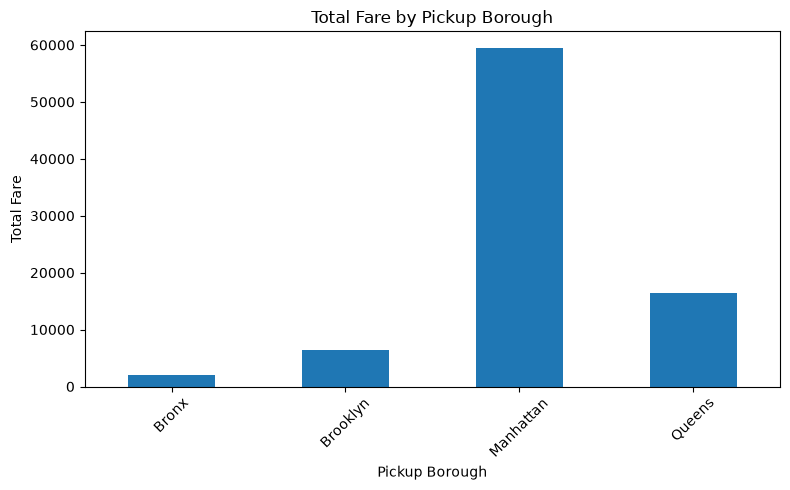

In [18]:
plt.figure(figsize=(8, 5))

borough_fare.plot(kind='bar')

plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.title("Total Fare by Pickup Borough")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
payment_counts = df['payment'].value_counts()

print("Trips by Payment Method:")
print(payment_counts)

Trips by Payment Method:
payment
credit card    4621
cash           1812
Name: count, dtype: int64


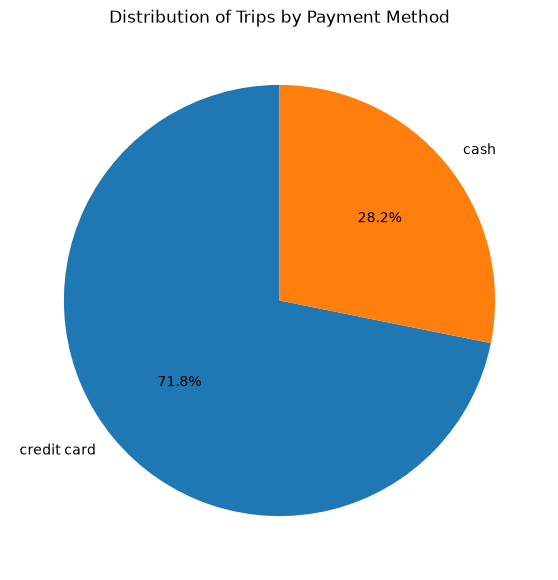

In [20]:
plt.figure(figsize=(7, 7))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Distribution of Trips by Payment Method")
plt.show()

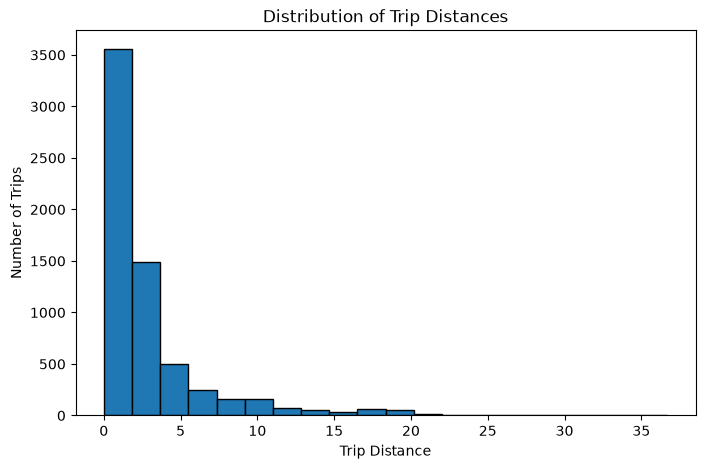

In [21]:
plt.figure(figsize=(8, 5))

plt.hist(df['distance'].dropna(), bins=20, edgecolor='black')

plt.xlabel("Trip Distance")
plt.ylabel("Number of Trips")
plt.title("Distribution of Trip Distances")

plt.show()

<Figure size 1000x500 with 0 Axes>

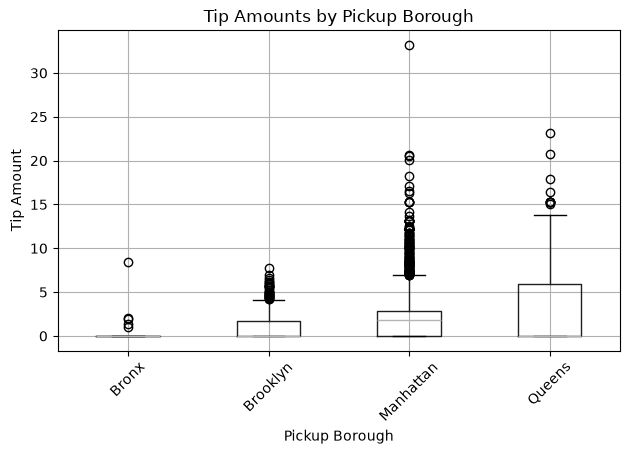

In [22]:
plt.figure(figsize=(10, 5))

df.boxplot(column='tip', by='pickup_borough')

plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.title("Tip Amounts by Pickup Borough")

plt.suptitle("")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

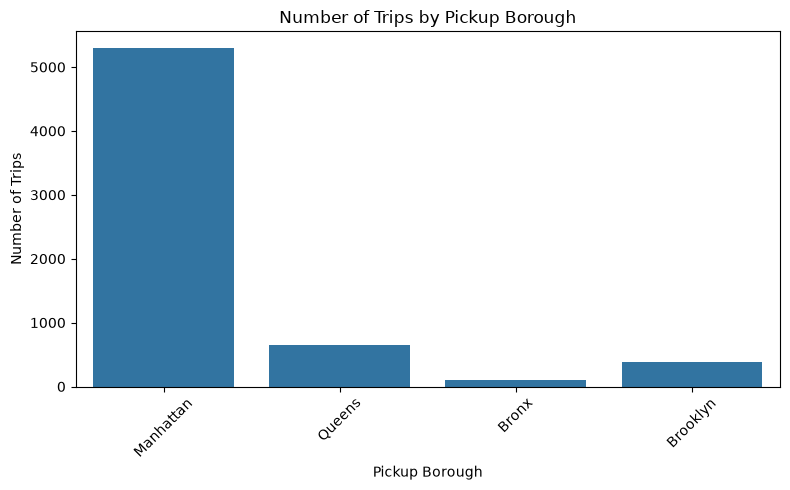

In [23]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='pickup_borough')

plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.title("Number of Trips by Pickup Borough")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

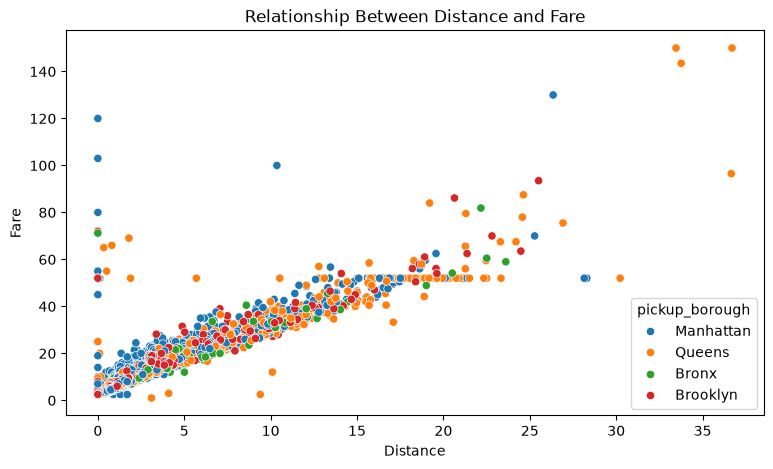

In [24]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough'
)

plt.xlabel("Distance")
plt.ylabel("Fare")
plt.title("Relationship Between Distance and Fare")

plt.show()

In [25]:
numerical_data = df[['distance', 'fare', 'tip', 'tolls', 'total']]

correlation_matrix = numerical_data.corr()

print("Correlation Matrix:")
print(correlation_matrix)

Correlation Matrix:
          distance      fare       tip     tolls     total
distance  1.000000  0.920108  0.452589  0.635267  0.904676
fare      0.920108  1.000000  0.488612  0.609307  0.974358
tip       0.452589  0.488612  1.000000  0.413619  0.646186
tolls     0.635267  0.609307  0.413619  1.000000  0.683142
total     0.904676  0.974358  0.646186  0.683142  1.000000


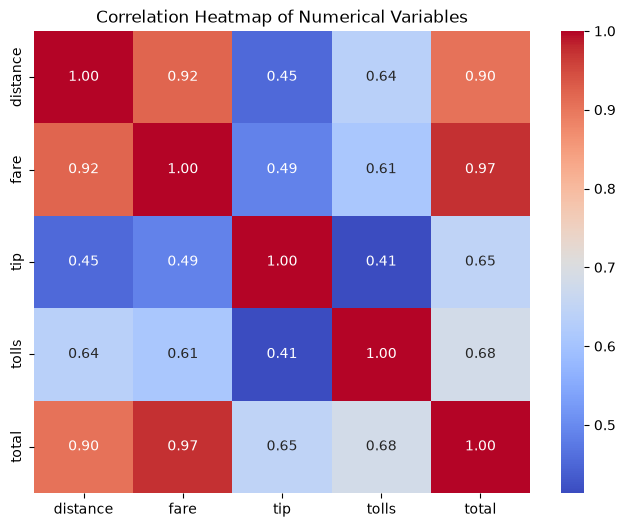

In [26]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

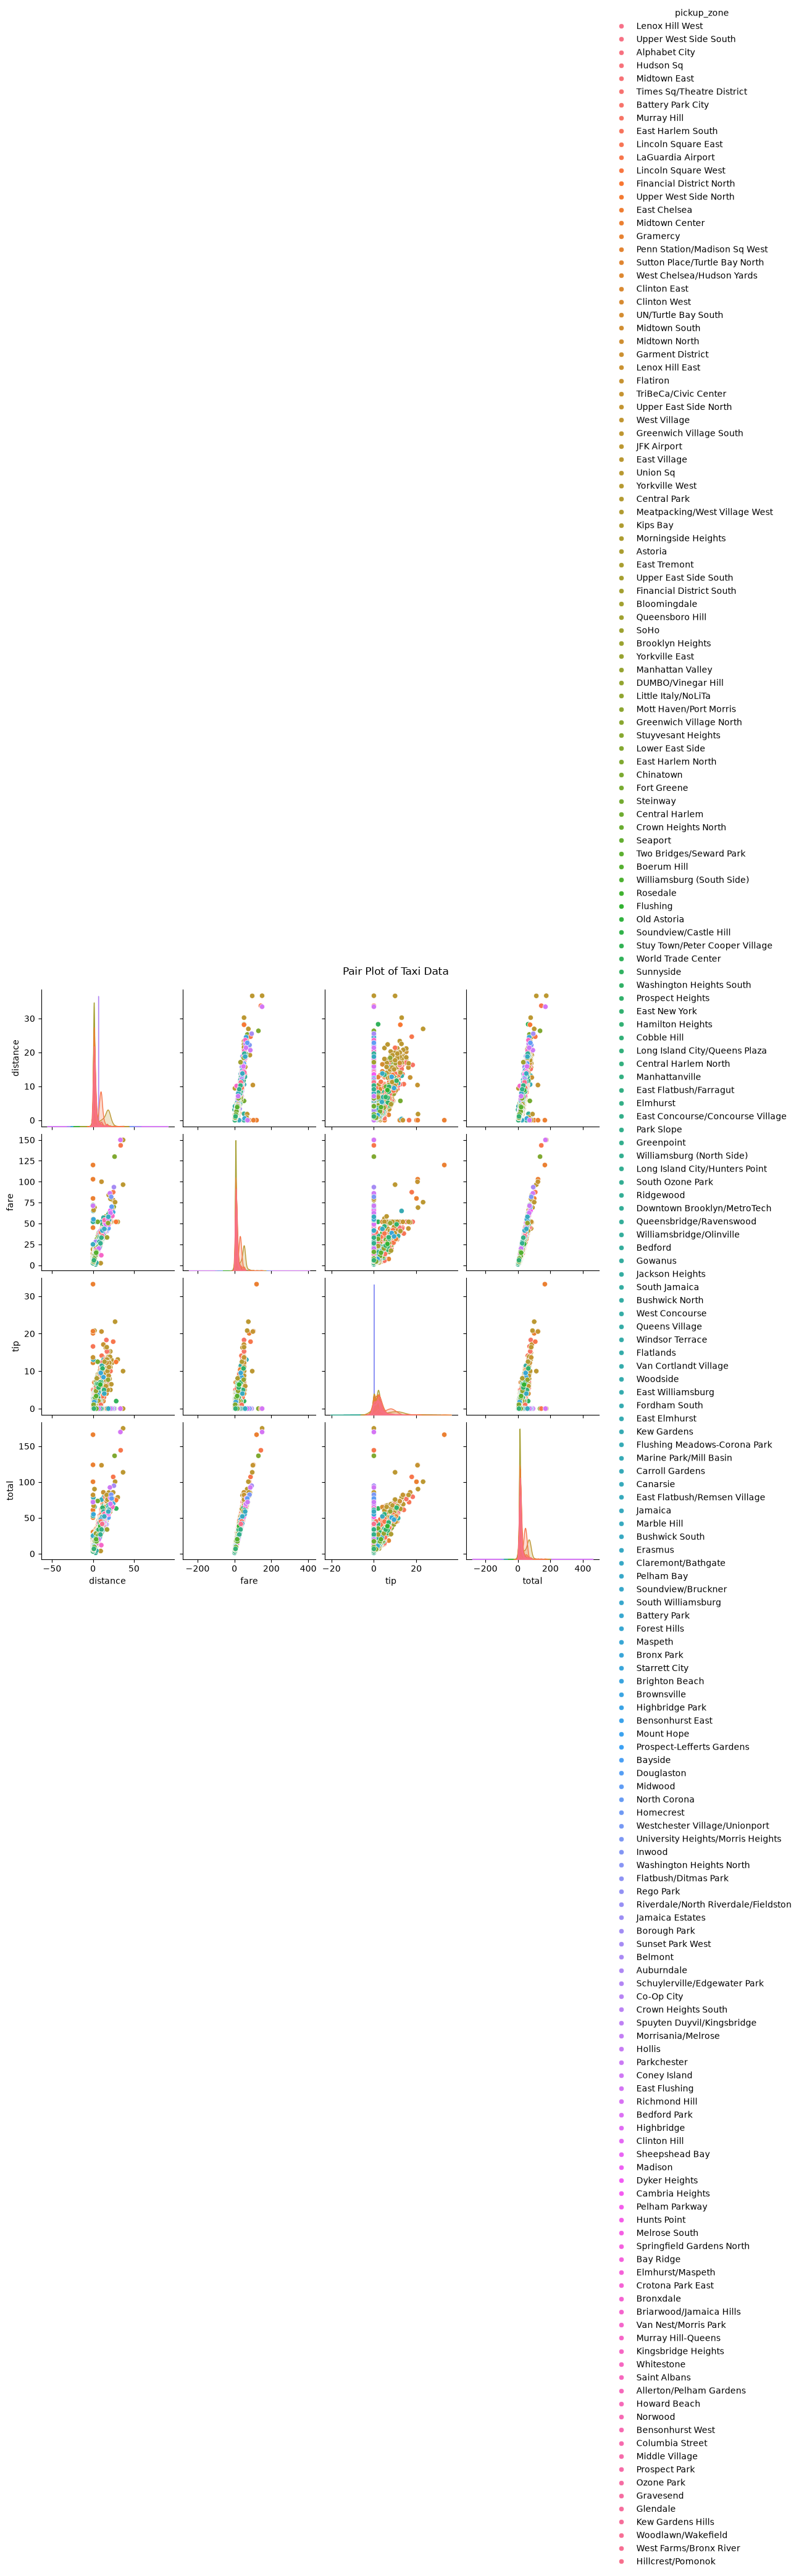

In [27]:
sns.pairplot(
    df[['distance', 'fare', 'tip', 'total', 'pickup_zone']],
    hue='pickup_zone'
)

plt.suptitle("Pair Plot of Taxi Data", y=1.02)
plt.show()

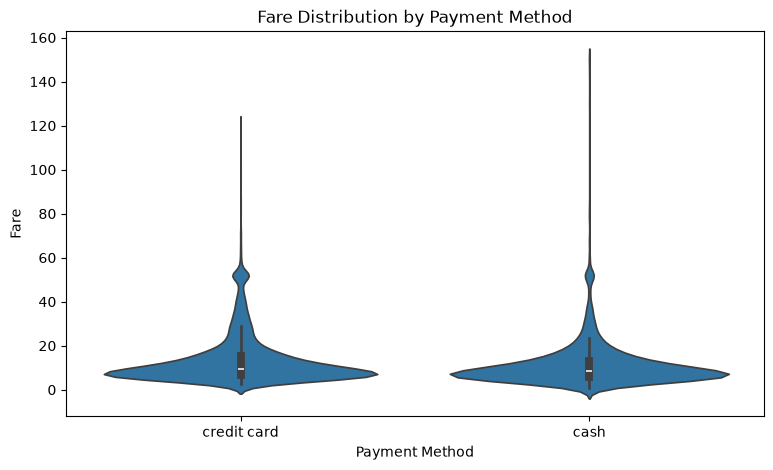

In [28]:
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=df,
    x='payment',
    y='fare'
)

plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.title("Fare Distribution by Payment Method")

plt.show()